# 01 Getting started with esc_etc

`esc_etc` is the exposure-time calculator for the ESC, the coronagraphic camera on Lazuli, a 3 m telescope. It answers two questions: what signal-to-noise ratio (SNR) a planet reaches in a given integration time, and how long it takes to reach a target SNR. This notebook goes from an empty session to both answers, then shows where the noise comes from.

> Requirements: `pip install -e .` from the repo root. The instrument configuration (UM 3 m ESC) ships inside the package, so nothing else needs to be installed.

In [1]:
import astropy.units as u
import esc_etc
from esc_etc import Simulation, use_lazuli_style

use_lazuli_style()      # house plotting style for the whole session
print('esc_etc', esc_etc.__version__)

esc_etc 0.1.0.post31+ge8d3be707.d20261010


## 1. A default simulation

`Simulation.from_default()` builds the four pieces of the calculator (telescope, sensor, scene, coronagraph) from the packaged configuration. The arguments below are the defaults, written out so you can see what a scene is: a host star of Vega magnitude -0.353, a planet 20 magnitudes fainter at 0.4 arcsec, a raw dark-hole contrast of 1e-8, and a post-processing gain of 10. Magnitudes are quoted in the ESC band unless you say otherwise (notebook 02).

In [2]:
sim = Simulation.from_default(
    hoststarmag=-0.353, planetdeltamag=20,
    contrast=1e-8, ppgain=10, separation=0.4,
)
sim

## 2. SNR for a given integration time

`get_snr` takes the total on-target time and the length of one detector frame. Both accept astropy quantities or plain numbers, which are read as seconds. The result is a dictionary: `snr`, the integrated planet signal and total noise in electrons, and `M`, the post-processing noise floor (more on that in notebook 03).

In [3]:
out = sim.get_snr(total_time=3600 * u.s, frame_time=100 * u.s)
print('SNR          :', round(out['snr'], 3))
print('signal [e-]  :', round(out['signal_e'], 1))
print('noise  [e-]  :', round(out['noise_e'], 1))

# plain floats are seconds; hours work too
assert sim.get_snr(3600, 100)['snr'] == out['snr']
assert sim.get_snr(1 * u.h, 100)['snr'] == out['snr']
assert abs(out['snr'] - 9.87) < 0.05, out['snr']

SNR          : 9.874
signal [e-]  : 8925.3
noise  [e-]  : 903.9


## 3. Integration time for a target SNR

`get_int_time_for_snr` is the inverse. `int_time` is rounded up to whole frames; `int_time_continuous` is the exact solution. The 3600 s above round-trips. SNR 5 is reached in about 30 s because it is only half of this scene's plateau of 10; the last factor of two toward the plateau takes most of the hour (notebook 03 explains the plateau).

In [4]:
back = sim.get_int_time_for_snr(out['snr'], frame_time=100)
five = sim.get_int_time_for_snr(5, frame_time=100)
print('time to recover the SNR above :', back['int_time'][0])
print('time to SNR 5                 :', five['int_time_continuous'][0])
assert abs(back['int_time'][0].value - 3600) < 1

time to recover the SNR above : 3600.0 s
time to SNR 5                 : 30.760556966659443 s


## 4. Where the noise comes from

`count_rate_components` returns the per-second electron rates inside the photometric aperture: the planet (`source`), zodiacal and exozodiacal light, residual speckles, and the host rate after the focal-plane mask. The speckle rate is `host x contrast x EE`, where EE is the fraction of a point source that falls inside the aperture (0.456 for the default aperture, see notebook 02): 5.4e8 x 1e-8 x 0.456 = 2.48 e/s. The planet gets the same EE factor, so with a contrast of 1e-8 and a planet 20 mag fainter the two rates come out equal, which is no accident: 10^(-0.4 x 20) = 1e-8.

source  : 2.479e+00 electron / s
zodi    : 8.646e-04 electron / s
exozodi : 3.190e-03 electron / s
speckle : 2.479e+00 electron / s
host    : 5.438e+08 electron / s


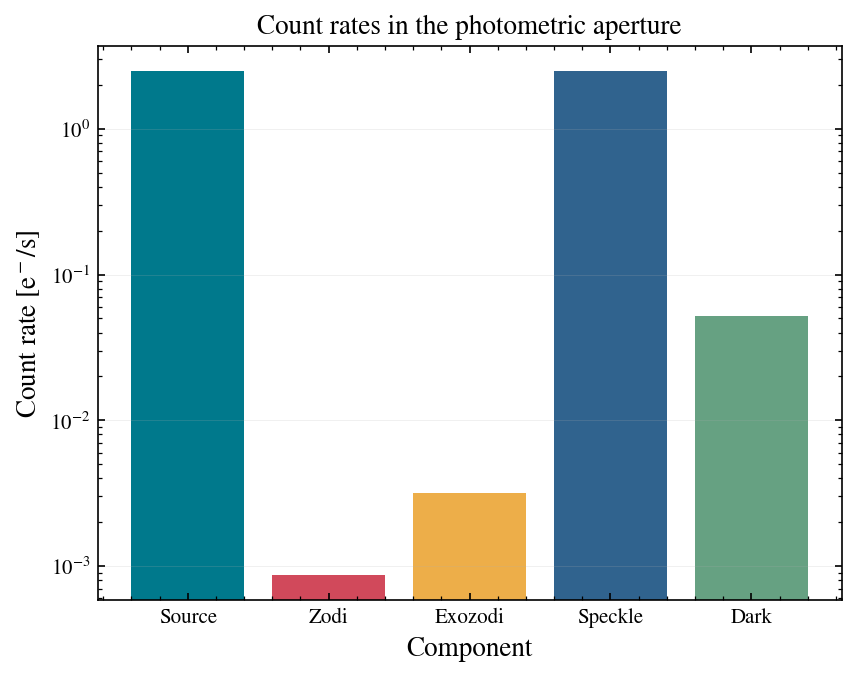

In [5]:
rates = sim.count_rate_components()
for name in ['source', 'zodi', 'exozodi', 'speckle', 'host']:
    print(f'{name:8s}: {getattr(rates, name):.3e}')

fig, ax = sim.plot_count_rates()
ax.set_title('Count rates in the photometric aperture');

## 5. Everything at once

`sim.plot()` draws the six standard panels. Every panel is also its own method (`sim.plot_snr_vs_time()`, `sim.plot_bandpass()`, and so on), and each accepts `ax=` so you can place it in your own figure.

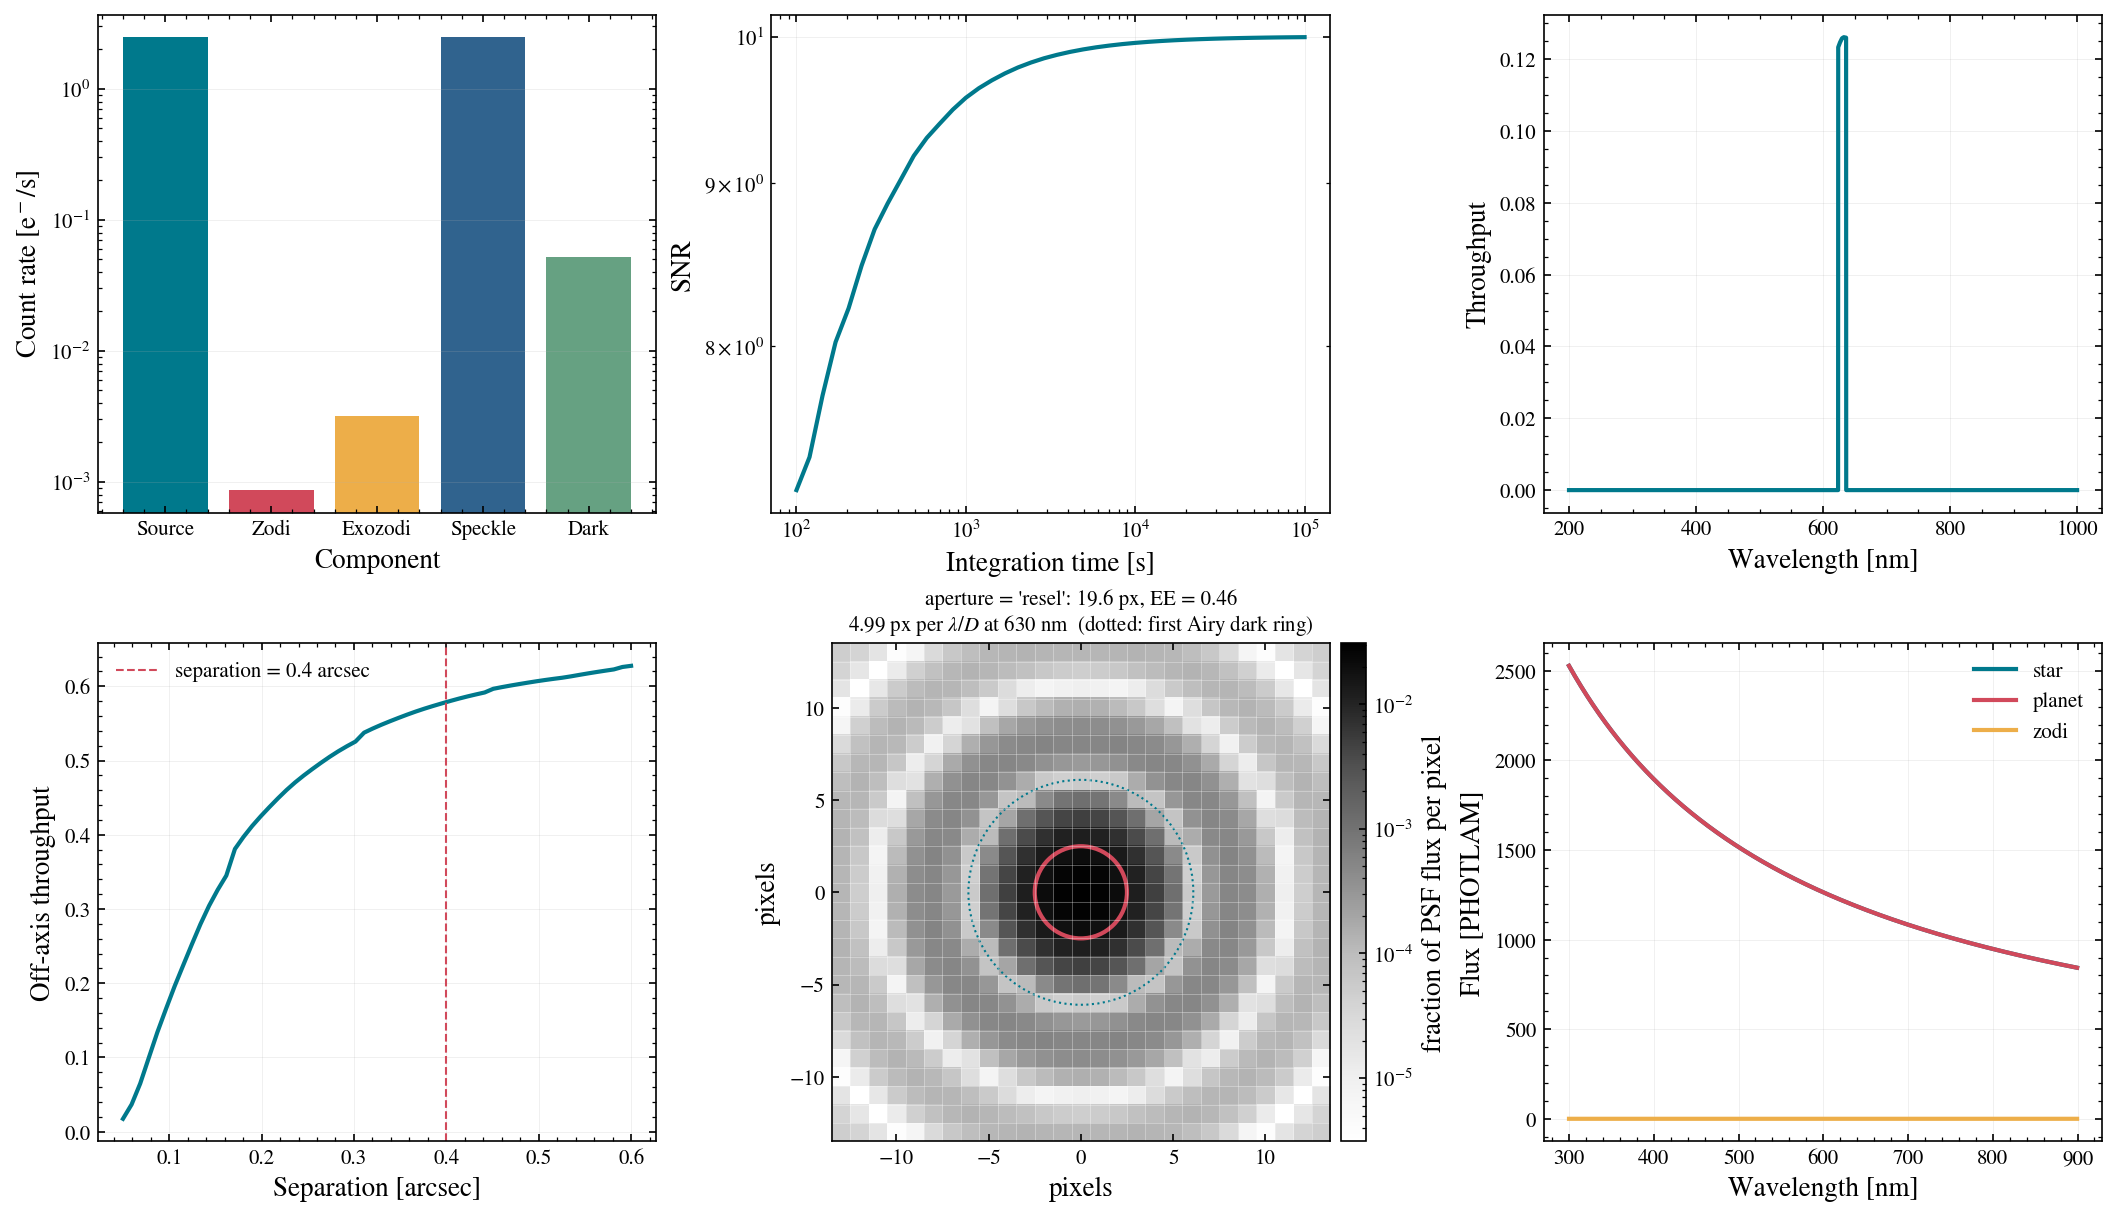

In [6]:
fig, axes = sim.plot()

Notebook 02 takes the simulation apart into its components and shows how to change parameters.